In [1]:
import kagglehub

import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

/Users/zarubin/PycharmProjects/CreditCardFraudDetection/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/zarubin/PycharmProjects/CreditCardFraudDetection/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/zarubin/.cache/kagglehub/datasets/mlg-ulb/creditcardfraud/versions/3


In [2]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

In [3]:
X = pd.read_csv(path + "/creditcard.csv")

In [4]:
TEST = 0.2
VAL = 0.2
TRAIN_VAL = 1 - TEST
RANDOM_SEED = 42

X_train_val, X_test = train_test_split(X, test_size=TEST, random_state=RANDOM_SEED, stratify=X['Class'])
X_train, X_val = train_test_split(X_train_val, test_size=VAL/TRAIN_VAL, random_state=RANDOM_SEED, stratify=X_train_val['Class'])

In [5]:
X_train.to_csv('../data/X_train.csv', index=False)
X_val.to_csv('../data/X_val.csv', index=False)
X_test.to_csv('../data/X_test.csv', index=False)

In [6]:
X_train.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
74456,55591.0,1.117794,0.256205,0.242660,1.093816,-0.030892,-0.456414,0.271483,-0.167214,-0.189264,...,0.093912,0.306353,-0.120715,0.118219,0.635185,-0.306978,0.029033,0.026853,47.92,0
96407,65755.0,-1.047459,1.403839,-1.024060,-1.099003,2.132122,3.727823,-1.269340,-1.348829,-1.096401,...,-1.141032,0.466258,0.091116,1.017133,-0.258486,0.285005,-0.053737,0.118632,1.50,0
198242,132394.0,0.160969,-3.749992,-3.540734,0.424158,-0.901679,-1.154844,1.857496,-0.740155,-1.027584,...,0.625777,0.033529,-1.059404,0.055980,0.303100,-0.320527,-0.234093,0.093084,1052.92,0
27489,34570.0,1.411564,-1.232946,0.801654,-1.282521,-1.943910,-0.830439,-1.210123,-0.103866,-1.520176,...,-0.260823,-0.510538,0.113410,0.321600,0.106883,-0.334594,0.039047,0.037220,55.00,0
121114,76076.0,-0.160939,0.705356,1.669306,0.941962,0.324622,-0.080444,0.619046,-0.160557,0.119227,...,-0.230701,-0.331014,-0.123881,-0.170461,-0.418866,-0.544911,0.032649,-0.057032,1.00,0


In [7]:
print(X_train.shape)
print(X_train.describe())
print(X_train.info())

(170883, 31)
                Time             V1             V2             V3  \
count  170883.000000  170883.000000  170883.000000  170883.000000   
mean    94864.790582       0.001683       0.001754      -0.001165   
std     47459.218514       1.959978       1.643975       1.521113   
min         0.000000     -56.407510     -72.715728     -33.680984   
25%     54229.000000      -0.919495      -0.601935      -0.891556   
50%     84793.000000       0.021721       0.064475       0.181141   
75%    139295.500000       1.316299       0.802718       1.027967   
max    172788.000000       2.451888      22.057729       9.382558   

                  V4             V5             V6             V7  \
count  170883.000000  170883.000000  170883.000000  170883.000000   
mean       -0.001944      -0.001328      -0.002825       0.000114   
std         1.417821       1.362528       1.321418       1.221464   
min        -5.683171     -42.147898     -26.160506     -43.557242   
25%        -0.852335

In [8]:
features = X_train.columns.tolist()
features.pop()

'Class'

In [9]:
def draw(X_draw):
    FEATURES = len(features)
    COLS = 3
    ROWS = (FEATURES + COLS - 1) // COLS


    fig, axes = plt.subplots(nrows=ROWS, ncols=COLS, figsize=(15 ,50))

    for i in range(ROWS):
        for j in range(COLS):
            axes[i, j].hist(X_draw[features[i * COLS + j]], bins=100)
            axes[i, j].set_title(features[i * COLS + j])

    plt.show()

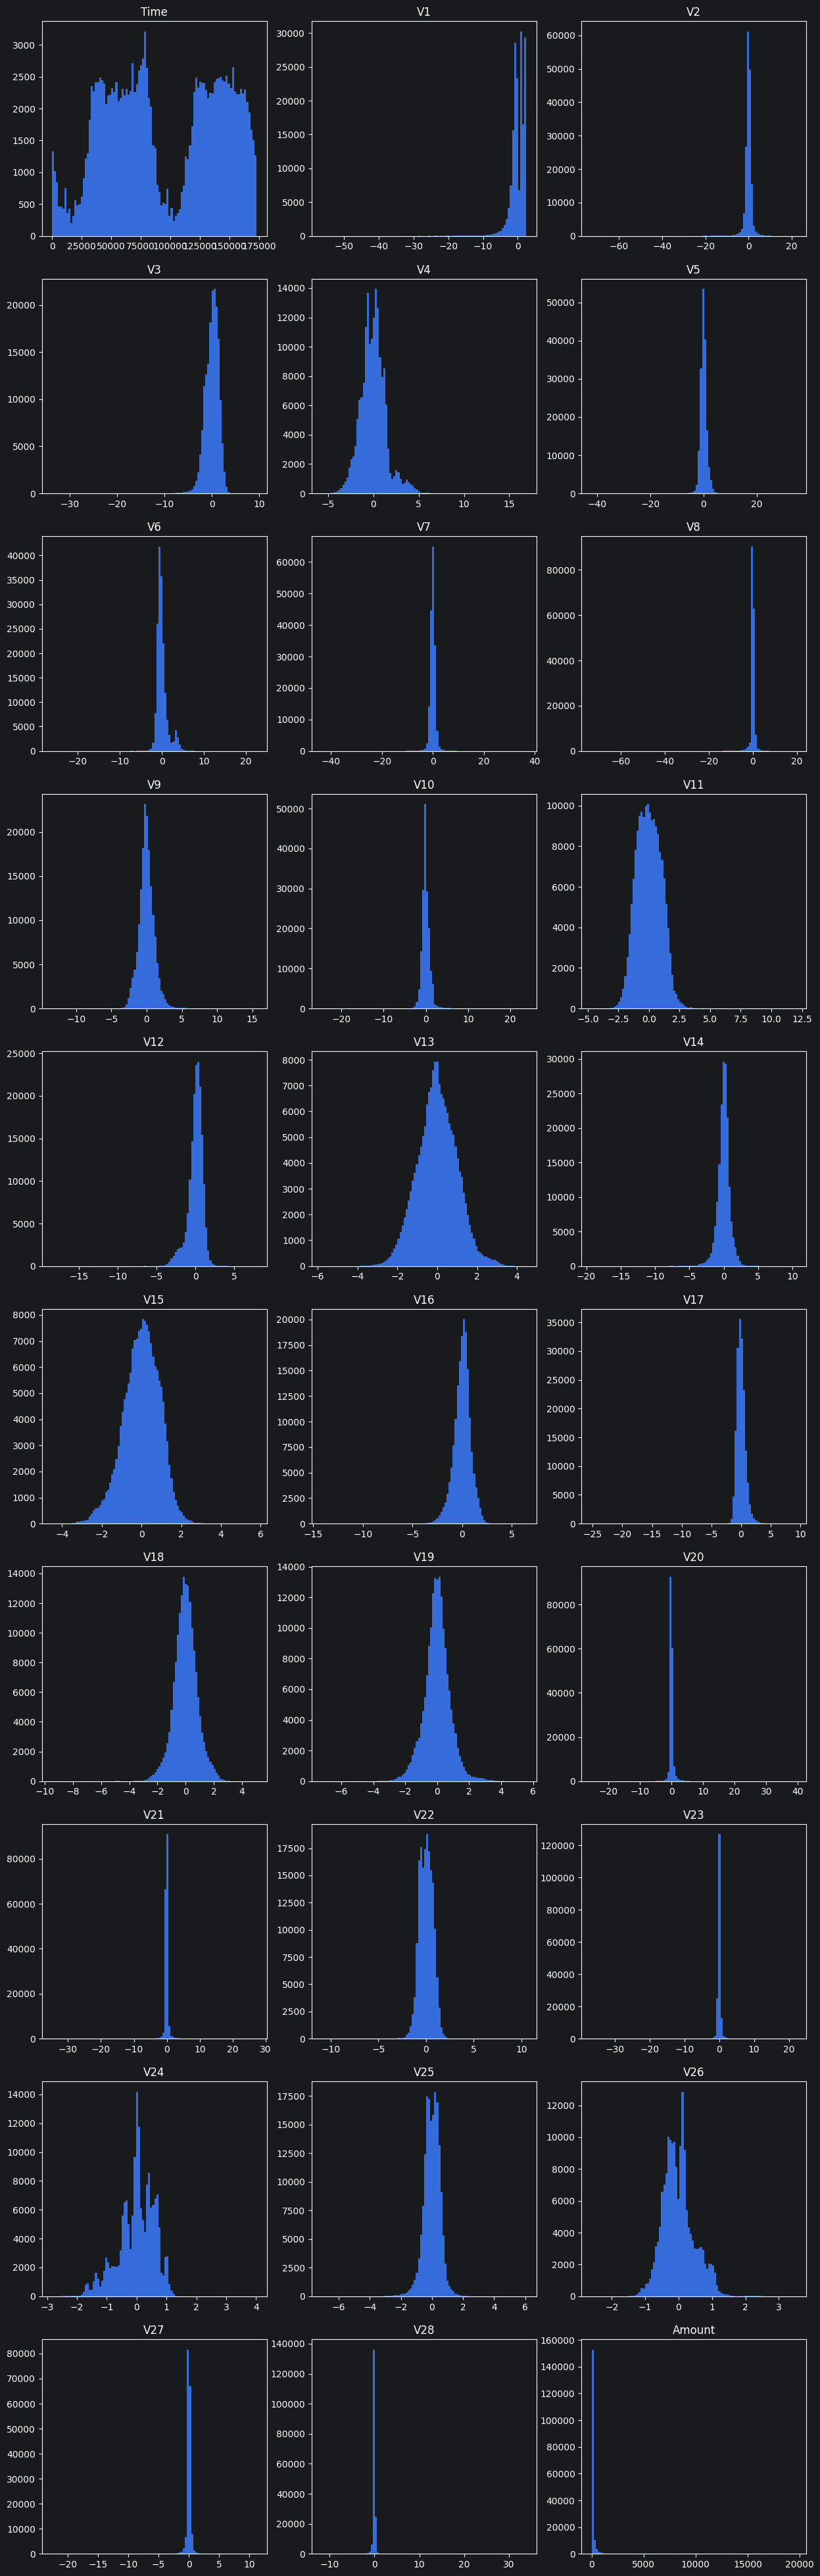

In [10]:
draw(X_train)

In [11]:
threshold = {
    'V1' : (-10, 10),
    'V2' : (-10, 10),
    'V3' : (-5, 5),
    'V4' : (-5, 5),
    'V5' : (-5, 5),
    'V6' : (-10, 10),
    'V7' : (-5, 5),
    'V8' : (-5, 5),
    'V9' : (-5, 5),
    'V10' : (-5, 5),
    'V11' : (-3.5, 3.5),
    'V12' : (-5, 5),
    'V13' : (-4, 4),
    'V14' : (-4, 4),
    'V15' : (-4, 4),
    'V16' : (-4, 4),
    'V17' : (-4, 4),
    'V18' : (-4, 4),
    'V19' : (-4, 4),
    'V20' : (-4, 4),
    'V21' : (-4, 4),
    'V22' : (-4, 4),
    'V23' : (-4, 4),
    'V24' : (-2, 2),
    'V25' : (-2.5, 2.5),
    'V26' : (-2, 2),
    'V27' : (-2.5, 2.5),
    'V28' : (-2, 2)
}

In [12]:
mask = pd.Series(True, index=X_train.index)
for col, (low, high) in threshold.items():
    mask &= X_train[col].between(low, high)

X_filtered = X_train[mask]

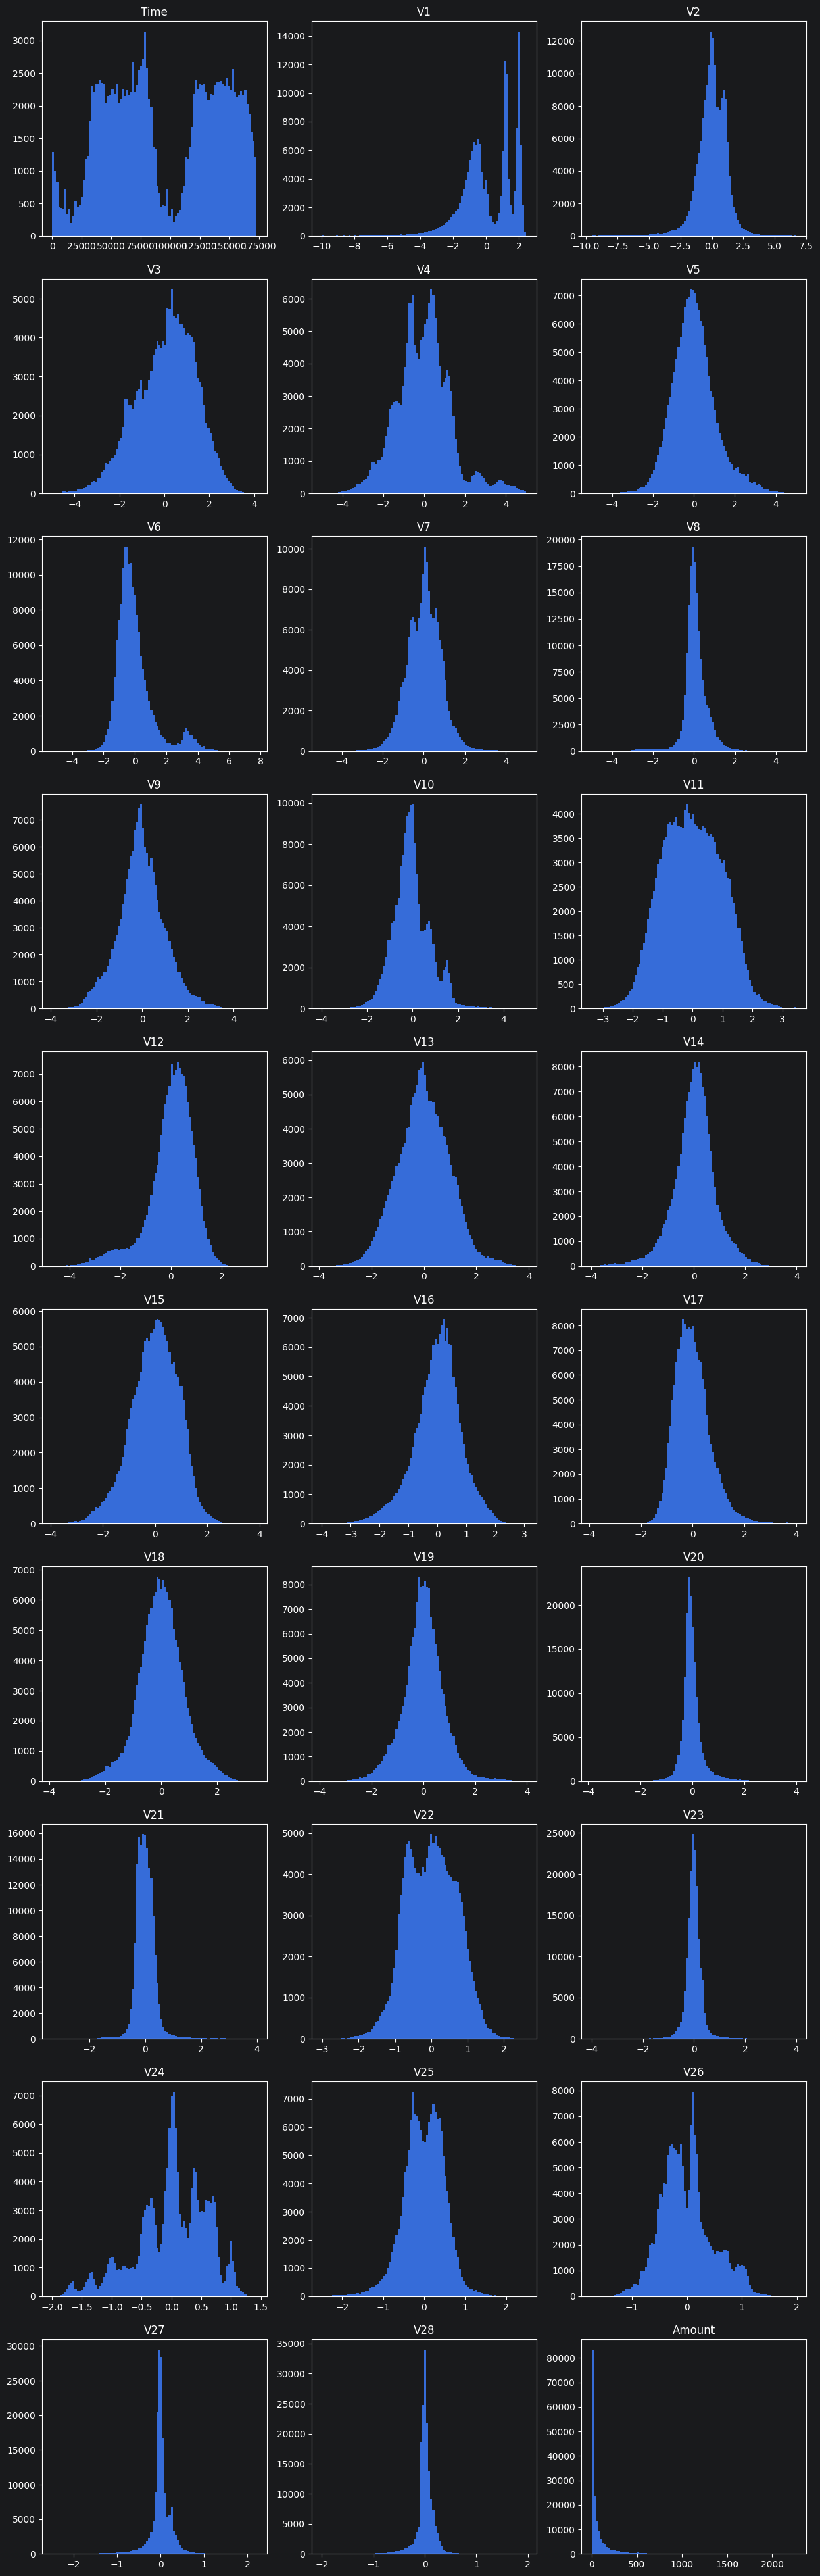

In [13]:
draw(X_filtered)

In [14]:
print(X_train.shape)
print(X_filtered.shape)
print(X_filtered.shape[0]/X_train.shape[0])

(170883, 31)
(165222, 31)
0.9668720703639332


In [15]:
print(X_filtered[X_filtered['Class'] == 1].shape[0]/X_train[X_train['Class'] == 1].shape[0])

0.13898305084745763


As we can see, almost all the frauds are filtered. That means that in this case frauds behave like outliers.
There are two possible ways:
- filter only genuine transactions
- do not filter at all
The first way is better since distinguishing uncommon transactions from others(even if they are genuine) is more important than identify genuine operations.

In [16]:
X_filtered_genuine = X_train[mask | (X_train['Class'] == 1)]
print(X_filtered_genuine.shape[0]/X_train.shape[0])
print(X_filtered_genuine[X_filtered_genuine['Class'] == 1].shape[0]/X_train[X_train['Class'] == 1].shape[0])

0.9683584674894519
1.0


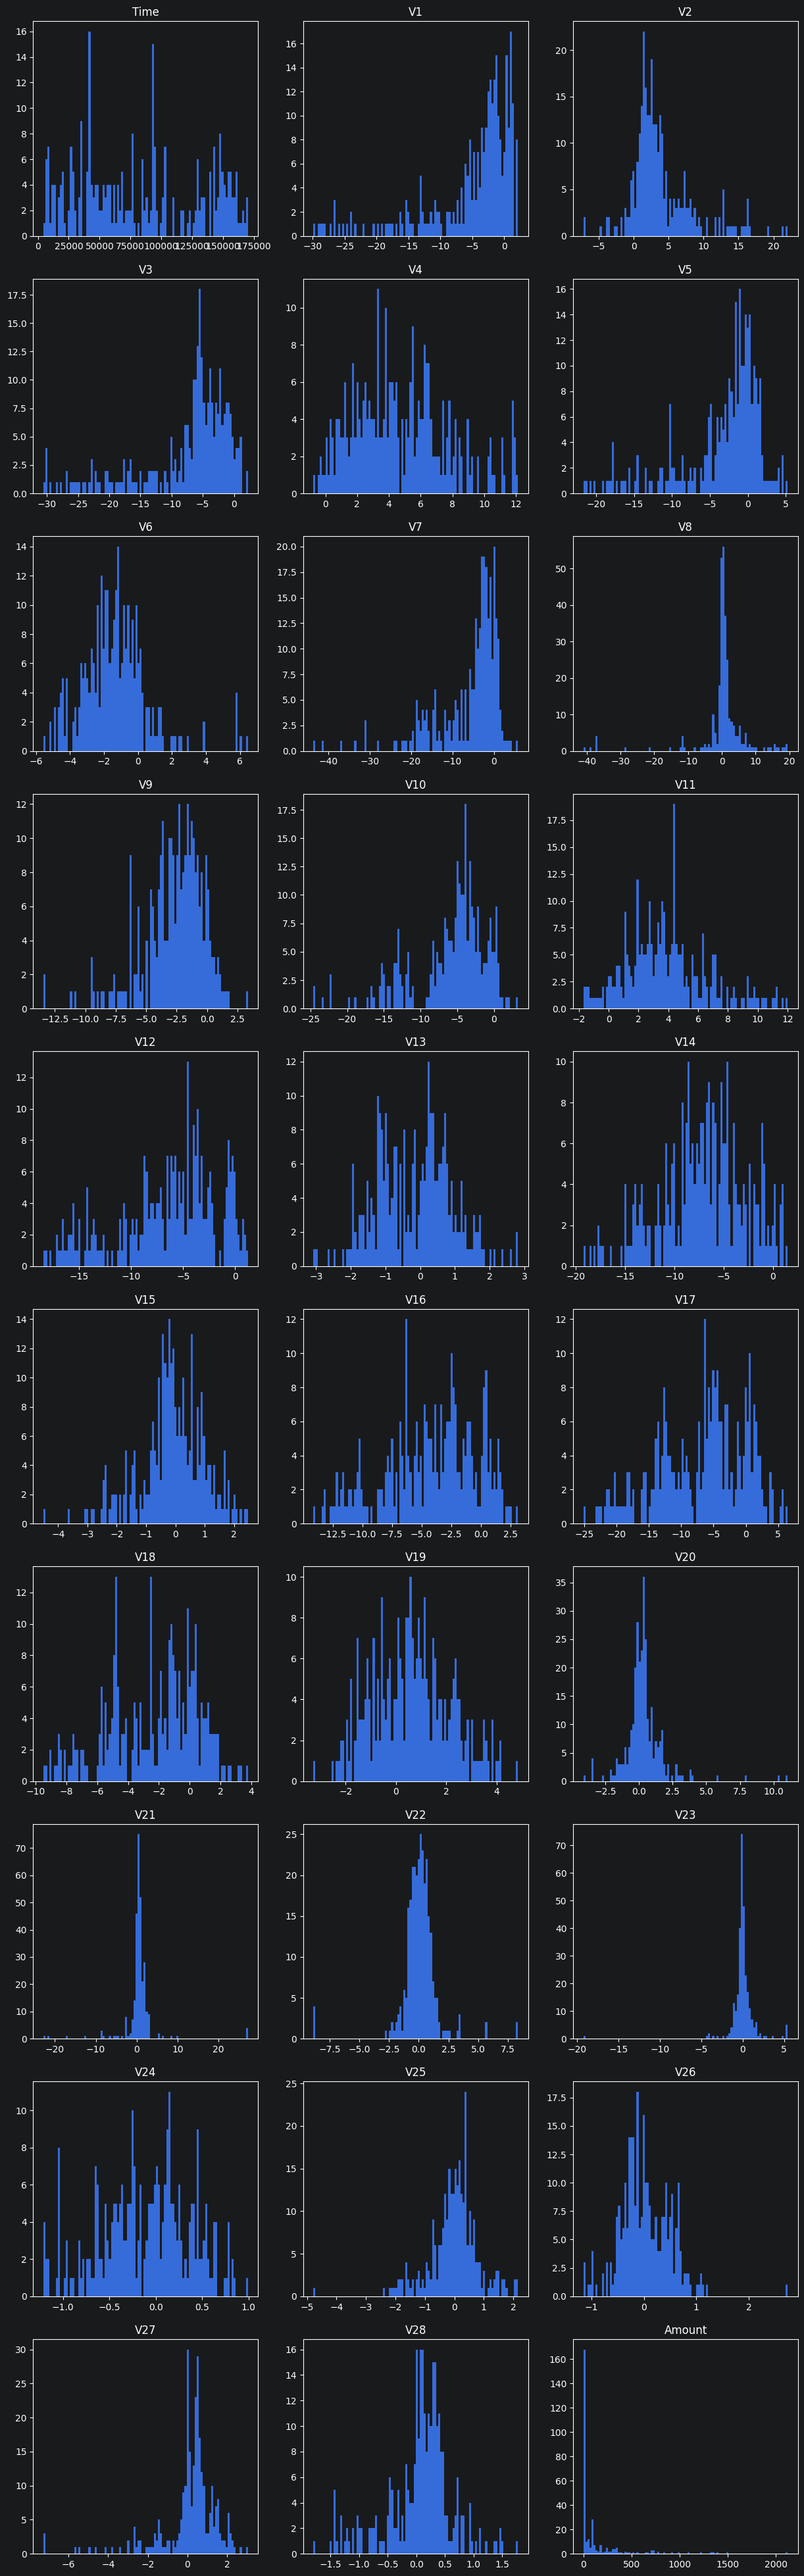

In [17]:
draw(X_filtered_genuine[X_filtered_genuine['Class'] == 1])

Since Time is an absolute counter spanning only 48 hours, it's reasonable to drop this column to avoid the model picking up spurious, non-generalizable temporal patterns.

In [18]:
print(X_filtered_genuine.duplicated().sum())

363


We should drop dublicates before excluding Time column as there can be different transactions with the same V1-V28.

In [19]:
X_noduplicates = X_filtered_genuine.drop_duplicates()

In [20]:
X_filtered_genuine_notime = X_noduplicates.drop('Time', axis=1)

In [21]:
print(X_filtered_genuine_notime.duplicated().sum() / X_filtered_genuine_notime.shape[0])

0.022130298643958986


Check for na.

In [22]:
print(X_filtered_genuine_notime.isna().sum() / X_filtered_genuine_notime.shape[0])

V1        0.0
V2        0.0
V3        0.0
V4        0.0
V5        0.0
V6        0.0
V7        0.0
V8        0.0
V9        0.0
V10       0.0
V11       0.0
V12       0.0
V13       0.0
V14       0.0
V15       0.0
V16       0.0
V17       0.0
V18       0.0
V19       0.0
V20       0.0
V21       0.0
V22       0.0
V23       0.0
V24       0.0
V25       0.0
V26       0.0
V27       0.0
V28       0.0
Amount    0.0
Class     0.0
dtype: float64


Since our features are PCA components (no clear domain meaning), we will use mean imputation for missing values in the final pipeline.

Let's study the correlation of features with the target(it allows to see linear dependencies)

<Axes: >

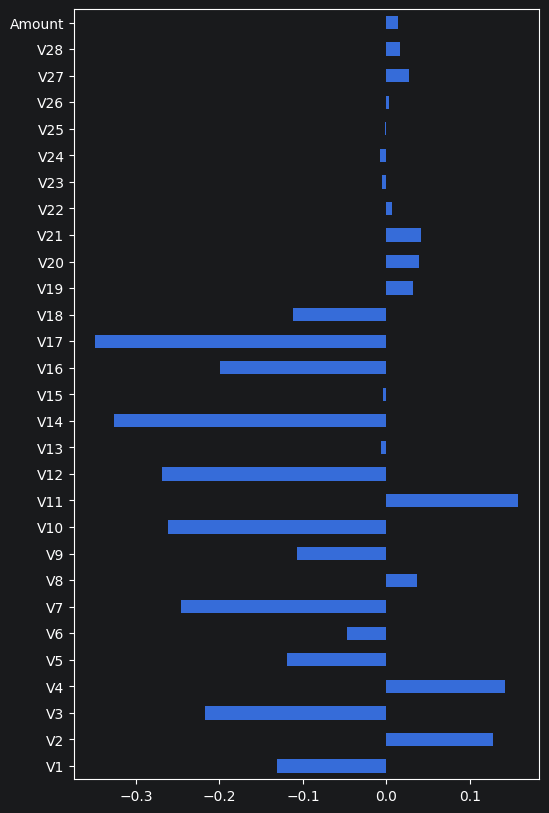

In [23]:
corr_table = X_filtered_genuine_notime.corr()['Class'].drop('Class')
corr_table.plot(kind='barh', figsize=(6, 10))

In [24]:
corr_table.sort_values(key=abs, ascending=False)

V17      -0.348484
V14      -0.325910
V12      -0.268808
V10      -0.261500
V7       -0.246458
V3       -0.216652
V16      -0.199766
V11       0.157653
V4        0.141939
V1       -0.130555
V2        0.127196
V5       -0.118503
V18      -0.112287
V9       -0.107323
V6       -0.047291
V21       0.041413
V20       0.038645
V8        0.036059
V19       0.032262
V27       0.026858
V28       0.015673
Amount    0.014432
V24      -0.007515
V22       0.007014
V13      -0.006184
V23      -0.004756
V15      -0.003708
V26       0.003650
V25      -0.001457
Name: Class, dtype: float64

In [25]:
selected_features = ['V17', 'V14', 'V12']

In [26]:
fig = px.scatter_3d(X_filtered_genuine_notime, x=selected_features[0], y=selected_features[1], z=selected_features[2], color='Class')
fig.write_html('../plots/selected_f.html')

Classes are poorly separated when features take values in the usual range (-4 to 4), i.e., when values are not extreme/outlier-like.

In [27]:
pca = PCA(n_components=3)
X_pca = pd.DataFrame(
    pca.fit_transform(X_filtered_genuine_notime.drop('Class', axis=1)),
    index=X_filtered_genuine_notime.index
)
X_pca['Class'] = X_filtered_genuine_notime['Class']

In [28]:
print(X_pca.columns.tolist())

[0, 1, 2, 'Class']


In [29]:
fig = px.scatter_3d(X_pca, x=0, y=1, z=2, color='Class')
fig.write_html('../plots/pca_both.html')

In [30]:
fig = px.scatter_3d(X_pca[X_pca['Class'] == 1], x=0, y=1, z=2, color='Class')
fig.write_html('../plots/pca_frauds.html')

Let us see the classes ratios.

In [31]:
print(X_filtered_genuine_notime[X_filtered_genuine_notime['Class'] == 1].shape[0]/X_filtered_genuine_notime.shape[0])
print(X_filtered_genuine_notime[X_filtered_genuine_notime['Class'] == 0].shape[0]/X_filtered_genuine_notime.shape[0])

print(X_filtered_genuine_notime[X_filtered_genuine_notime['Class'] == 1].shape[0])
print(X_filtered_genuine_notime[X_filtered_genuine_notime['Class'] == 0].shape[0])

0.001732147075033462
0.9982678529249666
286
164827


Classes are highly imbalanced so we should use metrics that either do not depend on classes proportion(roc-auc) or allow to adjust class balance(pr-auc)

Now make feature selection using baseline model

In [32]:
def compare(X_train_c, y_train_c, X_val_c, y_val_c):

    logreg_pipeline = Pipeline([
        ('scaler',  StandardScaler()),
        ('classifier', LogisticRegression(solver='lbfgs', max_iter=2000, C=0.5))
    ])

    if 'Time' in X_train_c.columns:
        X_train_c = X_train_c.drop('Time', axis=1)

    if 'Time' in X_val_c:
        X_val_c = X_val_c.drop('Time', axis=1)

    comparison_table = pd.DataFrame({
        'Feature': [],
        'PR-AUC train': [],
        'PR-AUC val': [],
        'ROC-AUC train': [],
        'ROC-AUC val': []
    })

    features = X_train_c.columns.tolist()

    for f in features:

        X_train_f = X_train_c.drop(f, axis=1)
        X_val_f = X_val_c.drop(f, axis=1)

        logreg_pipeline.fit(X_train_f, y_train_c)

        y_pred_train = logreg_pipeline.predict_proba(X_train_f)[:, 1]
        y_pred_val = logreg_pipeline.predict_proba(X_val_f)[:, 1]

        comparison_table.loc[len(comparison_table)] = (
            f,
            average_precision_score(y_train_c, y_pred_train),
            average_precision_score(y_val_c, y_pred_val),
            roc_auc_score(y_train_c, y_pred_train),
            roc_auc_score(y_val_c, y_pred_val),
        )

    return comparison_table

In [33]:
comparison_table = compare(X_filtered_genuine_notime.drop('Class', axis=1),
        X_filtered_genuine_notime['Class'],
        X_val.drop(['Class', 'Time'], axis=1),
        X_val['Class'])

In [34]:
comparison_table.describe()

,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val
count,29.000000,29.000000,29.000000,29.000000
mean,0.881457,0.559870,0.990650,0.970352
std,0.003280,0.018935,0.001615,0.005195
min,0.870125,0.497698,0.983381,0.946339
25%,0.881760,0.552279,0.990851,0.970758
50%,0.882409,0.559860,0.991152,0.971814
75%,0.883022,0.569533,0.991328,0.972381
max,0.884385,0.602475,0.991583,0.974576


In [35]:
comparison_table_pure = compare(X_train.drop("Class", axis=1),
                                X_train['Class'],
                                X_val.drop(['Class'], axis=1),
                                X_val['Class'])

In [36]:
comparison_table_pure.describe()

,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val
count,29.000000,29.000000,29.000000,29.000000
mean,0.789548,0.706848,0.985238,0.965278
std,0.003352,0.007353,0.002144,0.004869
min,0.778346,0.682352,0.977728,0.943008
25%,0.790142,0.705061,0.984480,0.964420
50%,0.790753,0.708909,0.985198,0.965543
75%,0.791121,0.709910,0.986613,0.967561
max,0.791731,0.718674,0.988269,0.971260


From the experiment above we can draw two conclusions.
- This analysis does not let us select any feature as more important: the highest and lowest PR-AUC values differ by about 0.15, which is not significant.
- This shows that filtering genuine transactions worsen model quality: Firstly, we observe overfitting. PR-AUC declines from 0.88 on train to 0.55 on validation (-0.33), while without filtering we have only 0.08 decline (0.78->0.70). Secondly, the quality is better in the second case: PR-AUC 0.55->0.70 (+0.15).
As we can see outliers significantly influence training quality. There are two ways 1) choose borders for features more properly 2) do not filter at all.

In [37]:
X_train_notime = X_train.drop('Time', axis=1)
X_train_notime = X_train_notime.drop_duplicates()
features_notime = features[1:]

In [38]:
Q1 = X_train_notime[features_notime[0:len(features_notime) -1]].quantile(0.25)
Q3 = X_train_notime[features_notime[0:len(features_notime) -1]].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [39]:
borders = pd.DataFrame({'lower': lower, 'upper': upper})
print(borders)

        lower     upper
V1  -4.288726  4.650964
V2  -2.756630  2.957574
V3  -3.700204  3.892456
V4  -3.288132  3.178565
V5  -2.652602  2.555370
V6  -2.495587  2.112185
V7  -2.251800  2.279310
V8  -1.004892  1.116315
V9  -2.527960  2.469306
V10 -2.047646  1.982508
V11 -3.026733  2.988938
V12 -1.949762  2.156614
V13 -2.634024  2.650490
V14 -1.799099  1.864265
V15 -2.450610  2.494560
V16 -1.977336  2.021781
V17 -1.809748  1.729142
V18 -2.005493  2.006931
V19 -1.848212  1.850631
V20 -0.736277  0.661815
V21 -0.845380  0.808953
V22 -2.134045  2.136251
V23 -0.629542  0.611097
V24 -1.548936  1.622389
V25 -1.323177  1.349830
V26 -1.182748  1.098990
V27 -0.318722  0.341685
V28 -0.252835  0.281190


In [40]:
# X_filtered_exp2 =
borders = {f: (lower[f], upper[f]) for f in lower.keys()}

mask = pd.Series(True, index=X_train_notime.index)
for f, (l, u) in borders.items():
    mask &= X_train_notime[f].between(l, u)

mask |= (X_train_notime['Class'] == 1)

X_filtered_exp2 = X_train_notime[mask]

In [41]:
comparison_table_better_filter = compare(X_filtered_exp2.drop('Class', axis=1),
                                         X_filtered_exp2['Class'],
                                         X_val.drop('Class', axis=1),
                                         X_val['Class'])

In [42]:
comparison_table_better_filter.describe()

,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val
count,29.000000,29.000000,29.000000,29.000000
mean,0.944265,0.159147,0.995577,0.959925
std,0.002195,0.032172,0.001133,0.004519
min,0.939344,0.085708,0.990002,0.942639
25%,0.943815,0.150298,0.995680,0.959508
50%,0.944247,0.154093,0.995907,0.959857
75%,0.945215,0.166849,0.995959,0.961035
max,0.951321,0.267803,0.996010,0.969051


This filtering even worse then the manual one.

Final decision on preprocessing

No outlier filtering will be applied: fraud transactions sit in the extreme tail of the PCA-transformed features, so filtering them out (even while keeping fraud rows) hurt validation PR-AUC in every experiment (0.71 unfiltered vs. 0.56 manual threshold vs. 0.16 IQR-based), a clear sign of overfitting to train. Time will be dropped, since it's just a raw counter over ~48 hours with no generalizable meaning. All other features are kept unchanged.